In [2]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

In [3]:
def neumann_poisson_modified(N,f):
    h = 1/N
    dx = dy = h
    main = 4 * np.ones(N*N)

    main[0] = main[N-1] = main[-1] = main[-N] = 2 # Corners
    main[1:N-1] = main[-N+1:-1] = main[N:-N:N] = main[2*N-1:-N:N] = 3 # Edges

    off1 = -1 * np.ones(N*N -1)

    off1[N-1:N*N-1:N] = 0

    offN = -1 * np.ones(N*N - N)

    # le modification
    off1 = np.append(off1, 0)
    offN = np.append(offN, 0)
    main = np.append(main,0) # inefficient but whatever.
    

    diagonals = [main,off1, off1, offN,offN]
    offsets = [0, -1,1, -N, N]

    A = sp.diags(diagonals, offsets, format = 'csr')

    A[:N*N, N*N] = 1
    A[N*N,:N*N] = 1

    
    b = np.zeros(N*N + 1)
    for i in range(1,N+1):
        for j in range(1,N+1):
            x = (i-1/2) * h
            y = (j-1/2) * h
            p = (i-1) * N + j - 1
            b[p] += f(x,y)

    b *= h**2

    u_int = spla.spsolve(A,b)
    return u_int, h


In [13]:
def diff_rec(U, V, N, R, stop, epsilon, k,rho, D):

    h = 20/N
    dx = dy = h
    main = 4 * np.ones(N*N)

    main[0] = main[N-1] = main[-1] = main[-N] = 2 # Corners
    main[1:N-1] = main[-N+1:-1] = main[N:-N:N] = main[2*N-1:-N:N] = 3 # Edges

    off1 = -1 * np.ones(N*N -1)

    off1[N-1:N*N-1:N] = 0

    offN = -1 * np.ones(N*N - N)

    diagonals = [main,off1, off1, offN,offN]
    offsets = [0, -1,1, -N, N]

    L = sp.diags(diagonals, offsets, format = 'csr')

    
    prevU = None
    prevV = None
    
    L = -L

    LHSfactorU = sp.identity(N*N ) - k * D * L
    LHSfactorV = sp.identity(N*N) - (k / epsilon) * L
    
    t = 0
    while ((prevU is None) or (thingymabob := max(max(abs(U-prevU)), max(abs(V-prevV)))) > stop) and t < 1000:
        URHS = U + k * (-(U - R) * (U*U - 1) - rho*(V - U))
        VRHS = V + k/epsilon * (U - V)

        prevU = U
        prevV = V
        U = spla.spsolve(LHSfactorU, URHS)
        V = spla.spsolve(LHSfactorV, VRHS)
        t += 1

    return U, V, t, thingymabob
    
        


## Question 1 b)

In [14]:
sp.identity(2).toarray()

array([[1., 0.],
       [0., 1.]])

In [14]:
def plot_sol(U,name, title):

    
    N = int(np.sqrt(U.shape[0]))
    U = U.reshape((N,N))

    h = 1/N
    
    X = np.linspace((1/2 * h) * 20 - 10 ,(1 - 1/2*h) * 20 - 10,N)
    Y = np.linspace((1/2 * h) * 20 - 10, (1 - 1/2*h) * 20 - 10, N)
    X,Y = np.meshgrid(X,Y, indexing='ij')
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    ax.plot_surface(X, Y, U, cmap='viridis', edgecolor='none')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel(name)
    plt.title(f"{title}")
    plt.tight_layout()
    plt.show()

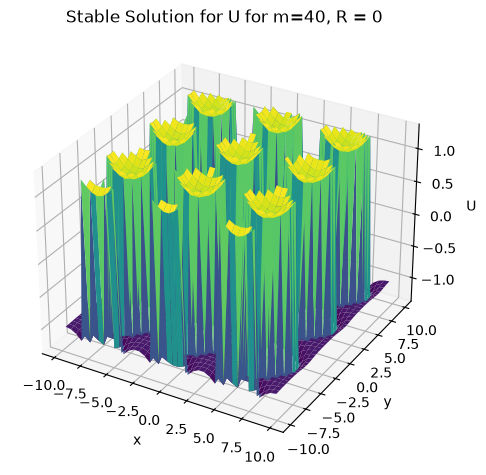

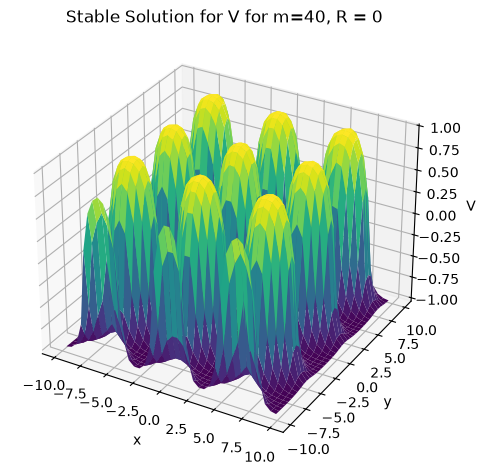

68
8.164039719815719e-07


In [15]:
R = 0
m = 40
stop = 1e-6
h = 1/m
U_innit = np.zeros(m*m)
f = lambda x,y : 0.1 * (np.cos(x) + np.sin(y))
epsilon = 1
k = 0.2
rho = 1
D = 0.04
for i in range(1,m+1):
    for j in range(1,m+1):
        x = ((i-1/2) * h) * 20 - 10
        y = ((j-1/2) * h) * 20 - 10
        p = (i-1) * m + j - 1
        U_innit[p] += f(x,y)


V_innit = np.ones(m*m) * 0.1
U, V, t, res = diff_rec(U_innit, V_innit, m, R, stop, epsilon,k, rho, D)
plot_sol(U, 'U', 'Stable Solution for U for m=40, R = 0')
plot_sol(V, 'V', 'Stable Solution for V for m=40, R = 0')
print(t)
print(res)

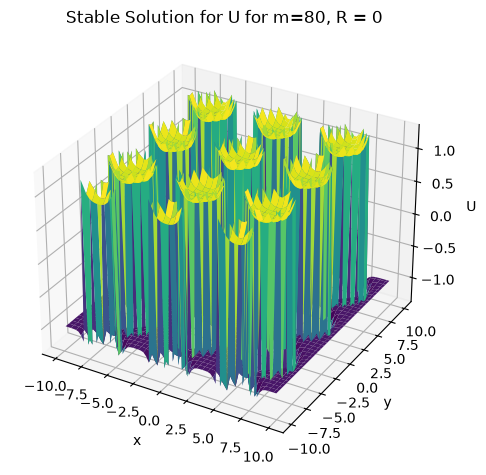

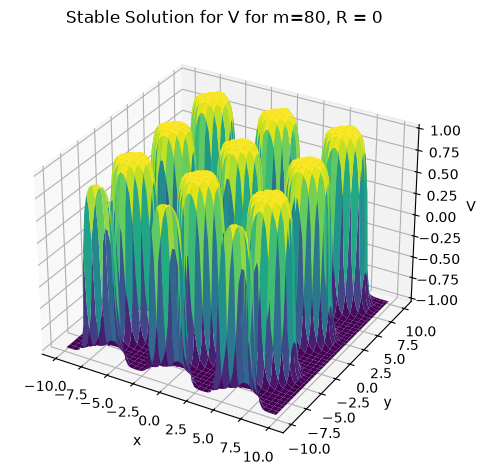

70
8.41769102422063e-07


In [16]:
R = 0
m = 80
stop = 1e-6
h = 1/m
U_innit = np.zeros(m*m)
f = lambda x,y : 0.1 * (np.cos(x) + np.sin(y))
epsilon = 1
k = 0.2
rho = 1
D = 0.04
for i in range(1,m+1):
    for j in range(1,m+1):
        x = ((i-1/2) * h) * 20 - 10
        y = ((j-1/2) * h) * 20 - 10
        p = (i-1) * m + j - 1
        U_innit[p] += f(x,y)


V_innit = np.ones(m*m) * 0.1
U, V, t, res = diff_rec(U_innit, V_innit, m, R, stop, epsilon,k, rho, D)
plot_sol(U, 'U', 'Stable Solution for U for m=80, R = 0')
plot_sol(V, 'V', 'Stable Solution for V for m=80, R = 0')
print(t)
print(res)

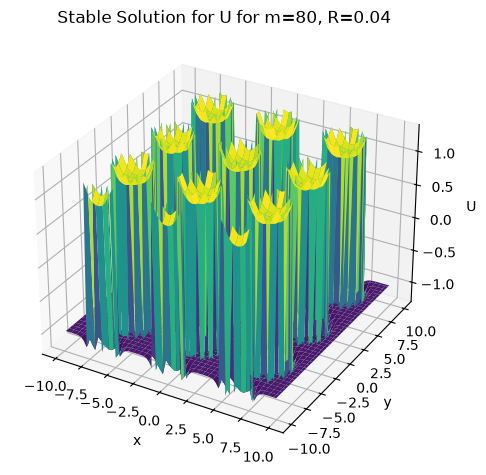

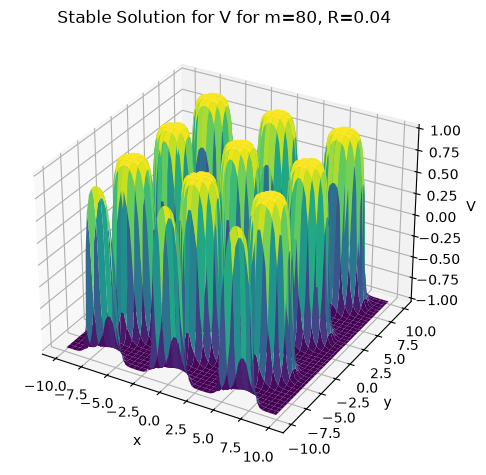

72
7.746116944540304e-07


In [18]:
R = 0.04
m = 80
stop = 1e-6
h = 1/m
U_innit = np.zeros(m*m)
f = lambda x,y : 0.1 * (np.cos(x) + np.sin(y))
epsilon = 1
k = 0.2
rho = 1
D = 0.04
for i in range(1,m+1):
    for j in range(1,m+1):
        x = ((i-1/2) * h) * 20 - 10
        y = ((j-1/2) * h) * 20 - 10
        p = (i-1) * m + j - 1
        U_innit[p] += f(x,y)


V_innit = np.ones(m*m) * 0.1
U, V, t, res = diff_rec(U_innit, V_innit, m, R, stop, epsilon,k, rho, D)
plot_sol(U, 'U', 'Stable Solution for U for m=80, R=0.04')
plot_sol(V, 'V', 'Stable Solution for V for m=80, R=0.04')
print(t)
print(res)

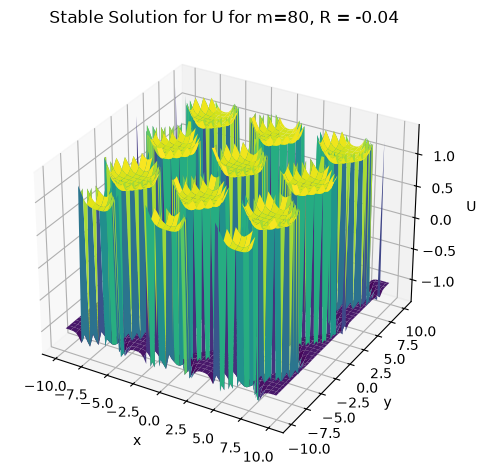

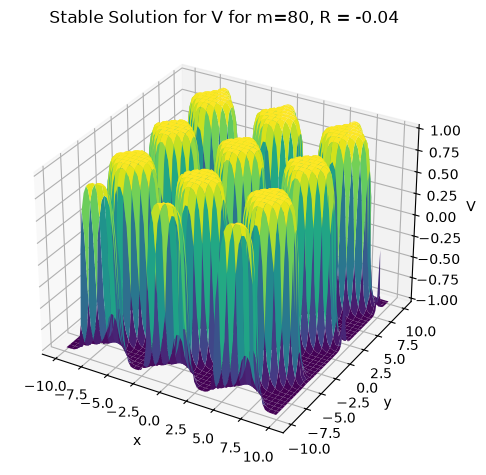

80
9.88424697756507e-07


In [ ]:
R = -0.04  
m = 80
stop = 1e-6
h = 1/m
U_innit = np.zeros(m*m)
f = lambda x,y : 0.1 * (np.cos(x) + np.sin(y))
epsilon = 1
k = 0.2
rho = 1
D = 0.04
for i in range(1,m+1):
    for j in range(1,m+1):
        
        x = ((i-1/2) * h) * 20 - 10
        y = ((j-1/2) * h) * 20 - 10
        p = (i-1) * m + j - 1
        U_innit[p] += f(x,y)


V_innit = np.ones(m*m) * 0.1
U, V, t, res = diff_rec(U_innit, V_innit, m, R, stop, epsilon,k, rho, D)
plot_sol(U, 'U', 'Stable Solution for U for m=80, R = -0.04')
plot_sol(V, 'V', 'Stable Solution for V for m=80, R = -0.04')
print(t)
print(res)

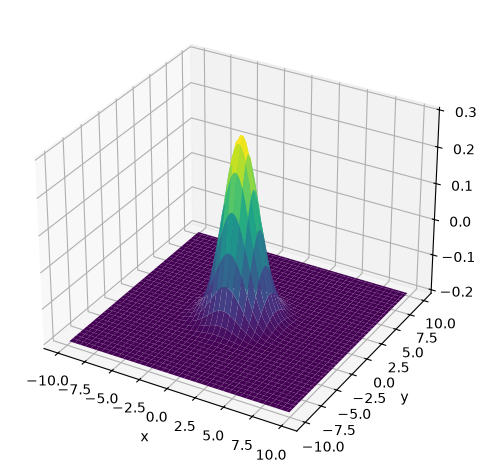

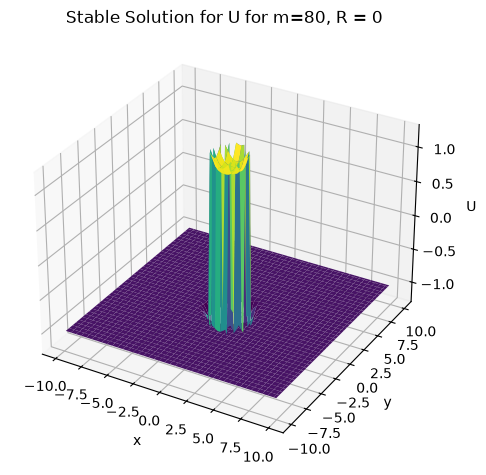

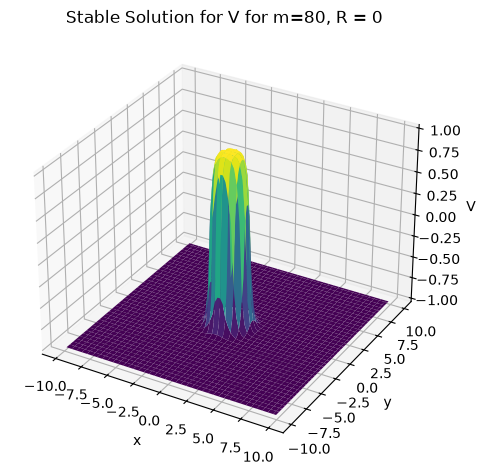

65
9.879849186544831e-07


In [20]:
R = 0
m = 80
stop = 1e-6
h = 1/m
U_innit = np.zeros(m*m)
f = lambda x,y : -0.2 + 1/2*np.exp( -(x*x + y*y)/4)

epsilon = 1
k = 0.2
rho = 1
D = 0.04
for i in range(1,m+1):
    for j in range(1,m+1):
        x = ((i-1/2) * h)* 20 - 10
        y = ((j-1/2) * h) * 20 - 10
        p = (i-1) * m + j - 1
        U_innit[p] += f(x,y)

plot_sol(U_innit, '','')

V_innit = np.ones(m*m) * 0.1
U, V, t, res = diff_rec(U_innit, V_innit, m, R, stop, epsilon,k, rho, D)
plot_sol(U, 'U', 'Stable Solution for U for m=80, R = 0')
plot_sol(V, 'V', 'Stable Solution for V for m=80, R = 0')
print(t)
print(res)

In [22]:
from scipy.integrate import solve_ivp

In [23]:

def RHS(t,U : np.ndarray, epsilon, h):
    u_next = np.roll(U, -1)
    u_next[-1] = 0
    u_prev = np.roll(U,1)
    u_prev[0] = 0

    second_deriv = epsilon * (u_prev - 2* U + u_next) / (h*h)
    first_deriv = (u_next * u_next- u_prev * u_prev)/ (4 * h)
    return second_deriv - first_deriv    



In [33]:
def do_the_thing(epsilon, n, t):

    h = 0.1 / (2**n)
    N = 2** n * 10 + 1 # if h = 1 you expect 2 points
    x_init = np.linspace(0, 1, N)
    U = np.sin(2* np.pi * x_init) + 1/2 * np.sin(np.pi * x_init)
    RHSWrapper = lambda t,U : RHS(t, U, epsilon, h)

    t_eval = np.array([t])
    sol = solve_ivp(RHSWrapper,(0,1), U,method="Radau", t_eval = t_eval)
    fig, axes = plt.subplots(1)
    Usol = sol.y[:, 0]
    axes.plot( x_init, Usol)
    axes.set_title(f"Solution of the borger equation at t = {t}, epsilon = {epsilon}, n = {n}")
    axes.set_xlabel("x")
    axes.set_ylabel("u")
    plt.show()
    return Usol

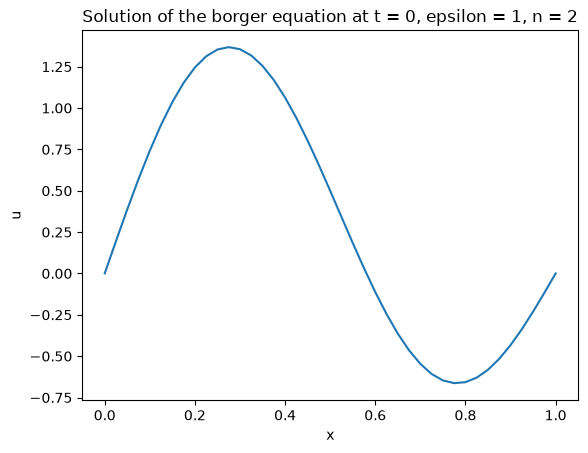

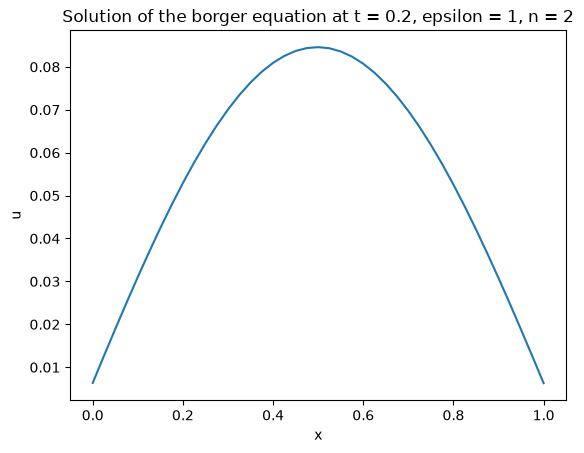

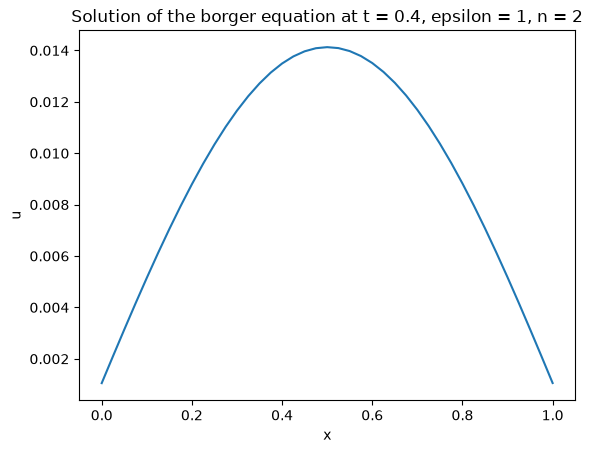

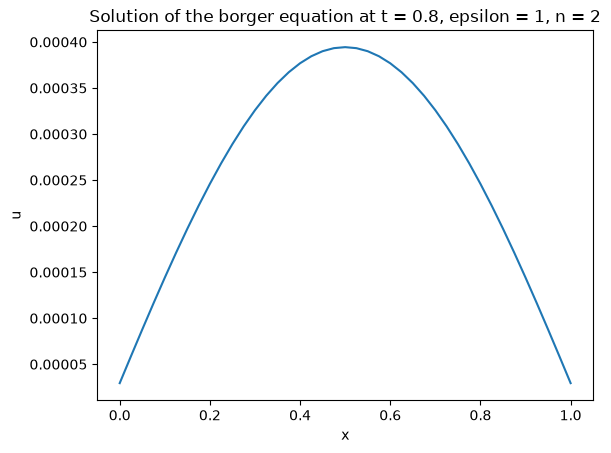

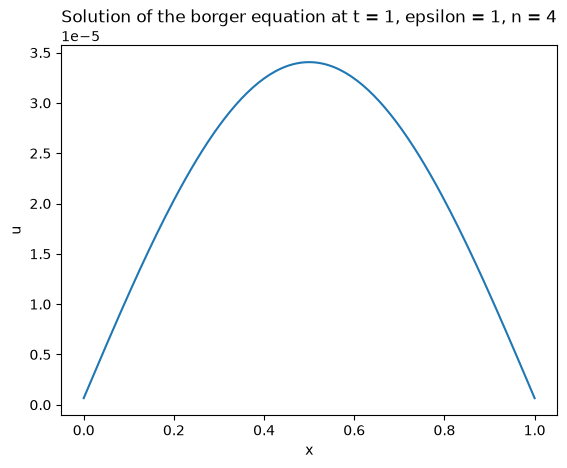

array([6.60492664e-07, 1.32073697e-06, 1.98048457e-06, 2.63948746e-06,
       3.29749789e-06, 3.95426849e-06, 4.60955238e-06, 5.26310323e-06,
       5.91467536e-06, 6.56402385e-06, 7.21090458e-06, 7.85507439e-06,
       8.49629107e-06, 9.13431356e-06, 9.76890195e-06, 1.03998176e-05,
       1.10268233e-05, 1.16496832e-05, 1.22681630e-05, 1.28820300e-05,
       1.34910533e-05, 1.40950037e-05, 1.46936540e-05, 1.52867788e-05,
       1.58741549e-05, 1.64555610e-05, 1.70307783e-05, 1.75995902e-05,
       1.81617823e-05, 1.87171429e-05, 1.92654627e-05, 1.98065350e-05,
       2.03401560e-05, 2.08661244e-05, 2.13842420e-05, 2.18943133e-05,
       2.23961460e-05, 2.28895509e-05, 2.33743417e-05, 2.38503356e-05,
       2.43173531e-05, 2.47752179e-05, 2.52237573e-05, 2.56628021e-05,
       2.60921867e-05, 2.65117491e-05, 2.69213312e-05, 2.73207784e-05,
       2.77099403e-05, 2.80886702e-05, 2.84568254e-05, 2.88142673e-05,
       2.91608614e-05, 2.94964773e-05, 2.98209888e-05, 3.01342739e-05,
      

In [34]:
do_the_thing(epsilon=1, n=2, t=0)
do_the_thing(epsilon=1, n=2, t=0.2)
do_the_thing(epsilon=1, n=2, t=0.4)
do_the_thing(epsilon=1, n=2, t=0.8)
do_the_thing(epsilon=1, n=4, t=1)


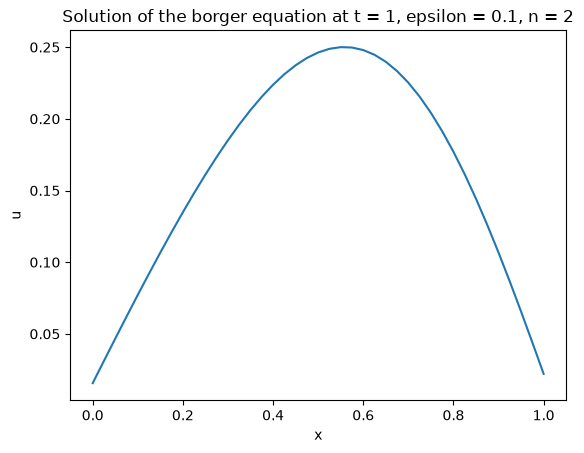

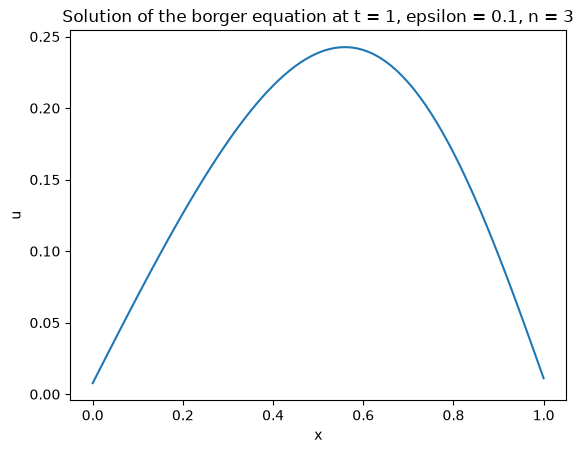

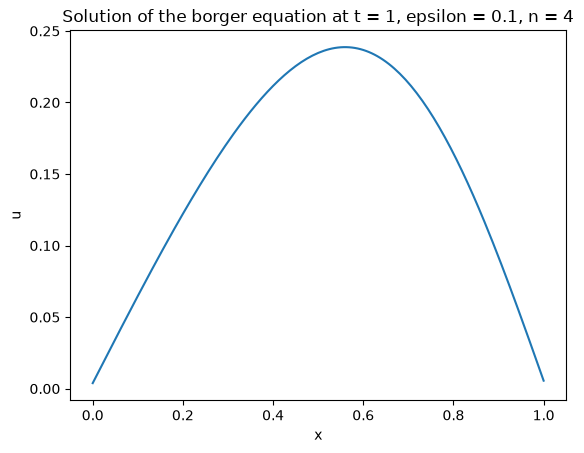

0.010965278237778636 0.005566302758958357


In [35]:

u2 = do_the_thing(epsilon=1e-1, n=2, t=1)
u3 = do_the_thing(epsilon=1e-1, n=3, t=1)
u4 = do_the_thing(epsilon=1e-1, n=4, t=1)


D_2 = np.max(np.abs(u3[::2] - u2))
D_3 = np.max(np.abs(u4[::2] - u3))

print(D_2, D_3)


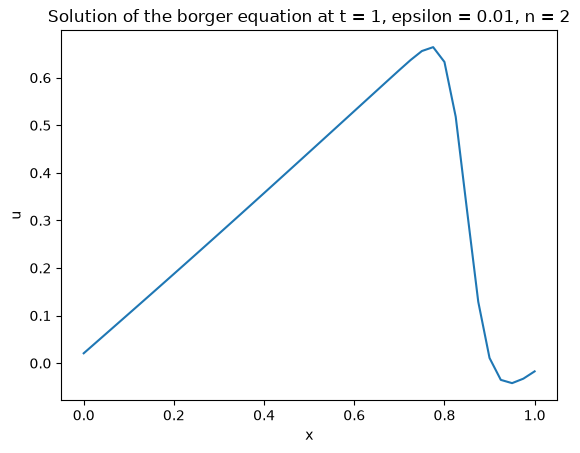

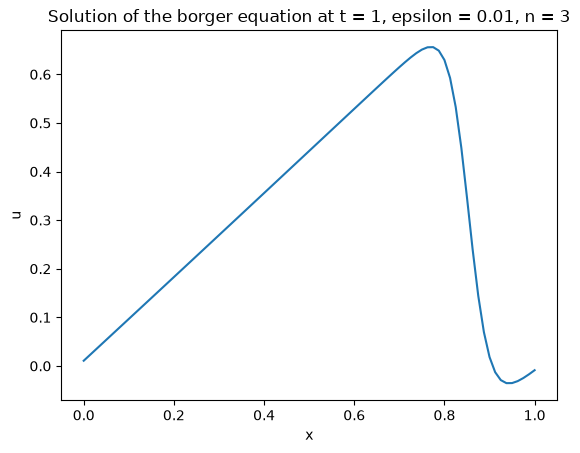

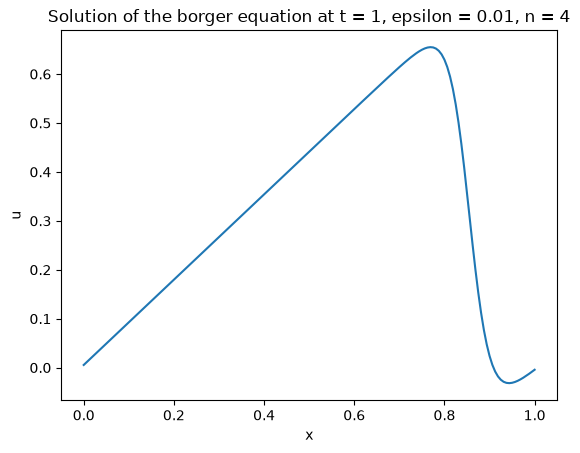

0.024587241799766513 0.010784115183698872


In [36]:

u2 = do_the_thing(epsilon=1e-2, n=2, t=1)
u3 = do_the_thing(epsilon=1e-2, n=3, t=1)
u4 = do_the_thing(epsilon=1e-2, n=4, t=1)


D_2 = np.max(np.abs(u3[::2] - u2))
D_3 = np.max(np.abs(u4[::2] - u3))

print(D_2, D_3)

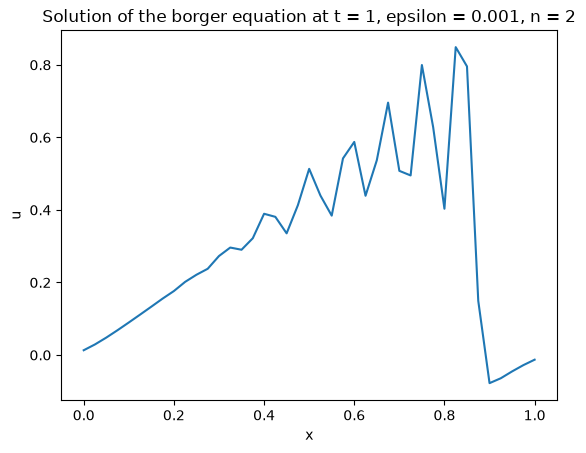

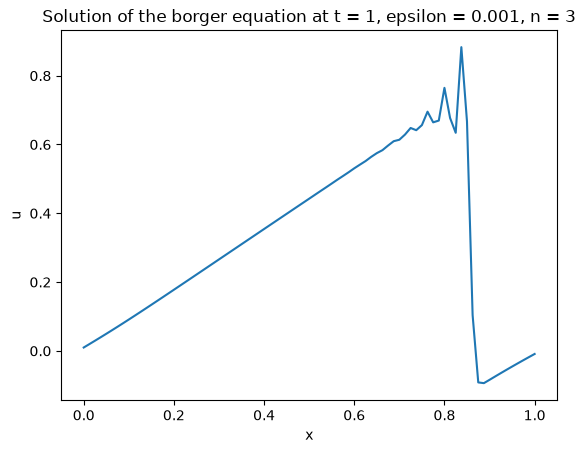

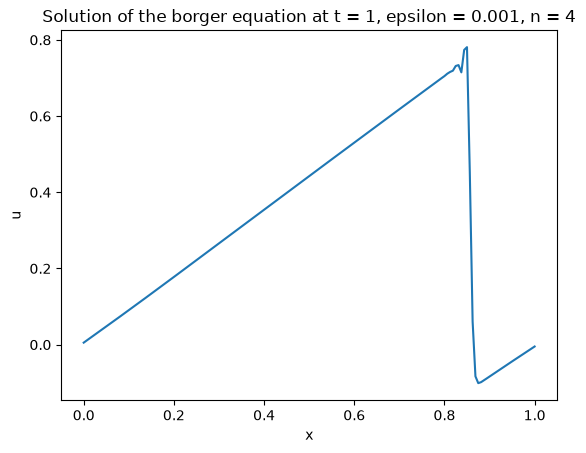

0.36139024996625824 0.16823383109873347


: 

In [ ]:

u2 = do_the_thing(epsilon=1e-3, n=2, t=1)
u3 = do_the_thing(epsilon=1e-3, n=3, t=1)
u4 = do_the_thing(epsilon=1e-3, n=4, t=1)

D_2 = np.max(np.abs(u3[::2] - u2))
D_3 = np.max(np.abs(u4[::2] - u3))

print(D_2, D_3)
